In [1]:
# If required, uncomment:
# %pip install pandas numpy scikit-learn matplotlib seaborn joblib

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

RANDOM_STATE = 42
TARGET = "Condition_Class"
CLASS_NAMES = ["Excellent", "Good", "Fair", "Poor"]

In [2]:
from sklearn.model_selection import GroupShuffleSplit

# Load existing datasets
train_df = pd.read_csv("../training_image_features.csv")
val_df = pd.read_csv("../validation_image_features.csv")
test_df = pd.read_csv("../testing_image_features.csv")

# Combine all existing data
all_df = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
)

# Ensure every row has an image ID
all_df = all_df.dropna(subset=["Image_ID"])
all_df["Image_ID"] = all_df["Image_ID"].astype(str)

# First split: 70% train, 30% temporary
split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, temp_idx = next(
    split1.split(all_df, groups=all_df["Image_ID"])
)

train_df = all_df.iloc[train_idx].copy()
temp_df = all_df.iloc[temp_idx].copy()

# Second split: 15% validation, 15% test
split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    split2.split(temp_df, groups=temp_df["Image_ID"])
)

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

# Save corrected datasets
train_df.to_csv("../training_image_features_grouped.csv", index=False)
val_df.to_csv("../validation_image_features_grouped.csv", index=False)
test_df.to_csv("../testing_image_features_grouped.csv", index=False)

print("Corrected dataset splits:")
print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

# Verify image separation
train_ids = set(train_df["Image_ID"])
val_ids = set(val_df["Image_ID"])
test_ids = set(test_df["Image_ID"])

print("\nImage overlap:")
print("Train-Val:", len(train_ids & val_ids))
print("Train-Test:", len(train_ids & test_ids))
print("Val-Test:", len(val_ids & test_ids))

Corrected dataset splits:
Training: (11465, 43)
Validation: (2410, 43)
Testing: (2644, 43)

Image overlap:
Train-Val: 0
Train-Test: 0
Val-Test: 0


In [3]:
EXCLUDE_COLUMNS = [
    TARGET,
    "Sample_ID",
    "Image_ID",

    # Target-derived features
    "Damage_Score",
    "Condition_Score",
    "Structural_Integrity",
    "Recovery_Pathway",
    "Reconditioning_Required",
    "Recovery_Potential",
    "Alternative_Use_Category",
    "Alternative_Use_Suitability",

    # Image dimensions
    "pixel_img_width",
    "pixel_img_height"
]

feature_columns = [c for c in train_df.columns if c not in EXCLUDE_COLUMNS]

X_train = train_df[feature_columns].copy()
y_train = train_df[TARGET].astype(str)

X_val = val_df[feature_columns].copy()
y_val = val_df[TARGET].astype(str)

X_test = test_df[feature_columns].copy()
y_test = test_df[TARGET].astype(str)

numeric_features = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = [c for c in feature_columns if c not in numeric_features]

print("Features:", len(feature_columns))
print("Numeric:", len(numeric_features))
print("Categorical:", len(categorical_features))

Features: 30
Numeric: 24
Categorical: 6


In [4]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [5]:
C_OPTIONS = [0.1, 1, 10, 100]
GAMMA_OPTIONS = ["scale", "auto"]

validation_results = []
candidate_models = {}

for C in C_OPTIONS:
    for gamma in GAMMA_OPTIONS:
        svm_pipeline = Pipeline(steps=[
            ("preprocessor", preprocessor),
            ("classifier", SVC(
                kernel="rbf",
                C=C,
                gamma=gamma,
                class_weight="balanced",
                probability=True,
                random_state=RANDOM_STATE
            ))
        ])

        svm_pipeline.fit(X_train, y_train)
        val_pred = svm_pipeline.predict(X_val)

        macro_f1 = f1_score(y_val, val_pred, average="macro", zero_division=0)
        accuracy = accuracy_score(y_val, val_pred)

        key = (C, gamma)
        candidate_models[key] = svm_pipeline
        validation_results.append({
            "C": C,
            "gamma": gamma,
            "validation_accuracy": accuracy,
            "validation_macro_f1": macro_f1
        })

results_df = pd.DataFrame(validation_results).sort_values(
    "validation_macro_f1", ascending=False
)
display(results_df)

best_row = results_df.iloc[0]
best_C = float(best_row["C"])
best_gamma = best_row["gamma"]
print("Selected C:", best_C)
print("Selected gamma:", best_gamma)

C:\Users\Ryan John\AppData\Roaming\Python\Python312\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\Ryan John\AppData\Roaming\Python\Python312\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\Ryan John\AppData\Roaming\Python\Python312\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\Ryan John\AppData\Roaming\Python\Python312\site-packages\sklearn\svm\_base.py:239: FutureWarning:

,C,gamma,validation_accuracy,validation_macro_f1
5,10.0,auto,0.999585,0.999702
7,100.0,auto,0.999585,0.999702
6,100.0,scale,0.997925,0.985831
4,10.0,scale,0.997095,0.984900
3,1.0,auto,0.989212,0.977195
2,1.0,scale,0.987552,0.975137
0,0.1,scale,0.851867,0.747253
1,0.1,auto,0.844398,0.734709


Selected C: 10.0
Selected gamma: auto


In [6]:
X_train_val = pd.concat([X_train, X_val], axis=0)
y_train_val = pd.concat([y_train, y_val], axis=0)

svm_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", SVC(
        kernel="rbf",
        C=best_C,
        gamma=best_gamma,
        class_weight="balanced",
        probability=True,
        random_state=RANDOM_STATE
    ))
])

svm_model.fit(X_train_val, y_train_val)
print("Final SVM model trained.")

C:\Users\Ryan John\AppData\Roaming\Python\Python312\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Final SVM model trained.


In [10]:
y_test_pred = svm_model.predict(X_test)

print("SVM Test Results")
print("----------------")
print("Accuracy:", round(accuracy_score(y_test, y_test_pred), 4))
print("Macro Precision:", round(precision_score(y_test, y_test_pred, average="macro", zero_division=0), 4))
print("Macro Recall:", round(recall_score(y_test, y_test_pred, average="macro", zero_division=0), 4))
print("Macro F1-score:", round(f1_score(y_test, y_test_pred, average="macro", zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred, labels=CLASS_NAMES, zero_division=0))

SVM Test Results
----------------
Accuracy: 0.9989
Macro Precision: 0.991
Macro Recall: 0.9993
Macro F1-score: 0.9951

Classification Report:
              precision    recall  f1-score   support

   Excellent       0.97      1.00      0.98        32
        Good       1.00      1.00      1.00       586
        Fair       1.00      1.00      1.00      1788
        Poor       1.00      1.00      1.00       238

    accuracy                           1.00      2644
   macro avg       0.99      1.00      1.00      2644
weighted avg       1.00      1.00      1.00      2644



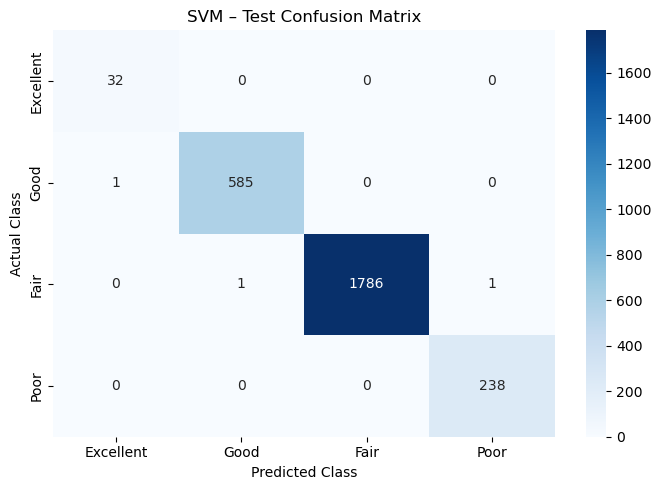

In [8]:
cm = confusion_matrix(y_test, y_test_pred, labels=CLASS_NAMES)

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("SVM – Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [9]:
os.makedirs("saved_models", exist_ok=True)

MODEL_PATH = os.path.join("saved_models", "codd_svm_pipeline.joblib")
joblib.dump(svm_model, MODEL_PATH)

print("Saved SVM pipeline to:", MODEL_PATH)
print("The saved pipeline includes preprocessing and the trained SVM.")

Saved SVM pipeline to: saved_models\codd_svm_pipeline.joblib
The saved pipeline includes preprocessing and the trained SVM.
